<a href="https://colab.research.google.com/github/titarzra/Tugas-MachineLearning_TitaRizekyRahmadina_202343500097/blob/main/Bab_07_Evaluasi_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Bagian A — Implementasi Python

### Praktikum 7.1 Persiapan Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, precision_score, recall_score, f1_score,
                             roc_curve, auc, precision_recall_curve, classification_report,
                             average_precision_score, ConfusionMatrixDisplay)

### Praktikum 7.2 Import Dataset

In [2]:
X, y = make_classification(n_samples=1000, n_features=10, weights=[0.7, 0.3], random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

### Praktikum 7.3 Preprocessing dan Training Model

In [3]:
model = LogisticRegression().fit(X_train, y_train)
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

### Praktikum 7.4 Evaluasi

In [4]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall   :", round(recall_score(y_test, y_pred), 3))
print("F1-Score :", round(f1_score(y_test, y_pred), 3))
print(classification_report(y_test, y_pred))

# Stratified k-Fold Cross-Validation untuk perbandingan model
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
skor_cv = cross_val_score(model, X, y, cv=skf, scoring="f1")
print("F1-Score tiap fold:", np.round(skor_cv, 3))
print("Rata-rata F1-Score:", round(skor_cv.mean(), 3), "+/-", round(skor_cv.std(), 3))

Confusion Matrix:
 [[193  16]
 [ 20  71]]
Precision: 0.816
Recall   : 0.78
F1-Score : 0.798
              precision    recall  f1-score   support

           0       0.91      0.92      0.91       209
           1       0.82      0.78      0.80        91

    accuracy                           0.88       300
   macro avg       0.86      0.85      0.86       300
weighted avg       0.88      0.88      0.88       300

F1-Score tiap fold: [0.821 0.793 0.771 0.807 0.803]
Rata-rata F1-Score: 0.799 +/- 0.017


### Praktikum 7.5 Visualisasi

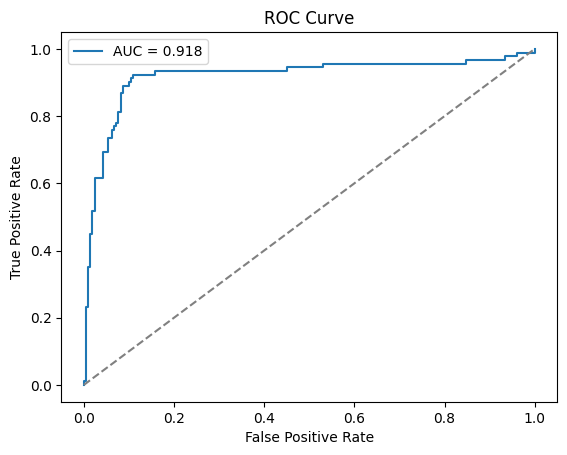

In [5]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], '--', color="gray")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve"); plt.legend()
plt.show()

## Bagian B — Latihan Praktikum

In [6]:
from sklearn.datasets import load_breast_cancer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

bc = load_breast_cancer(as_frame=True)
Xb = bc.data
yb = 1 - bc.target          # 1 = ganas (positif), 0 = jinak
Xb_train, Xb_test, yb_train, yb_test = train_test_split(Xb, yb, test_size=0.3, stratify=yb, random_state=42)
print("Proporsi ganas pada train/test:", yb_train.mean().round(3), "/", yb_test.mean().round(3))

models = {
    "Logistic Regression": Pipeline([("sc", StandardScaler()), ("clf", LogisticRegression(max_iter=1000))]),
    "Decision Tree (depth=4)": DecisionTreeClassifier(max_depth=4, random_state=42),
}
hasil, proba, pred = [], {}, {}
for nama, m in models.items():
    m.fit(Xb_train, yb_train)
    pred[nama] = m.predict(Xb_test)
    proba[nama] = m.predict_proba(Xb_test)[:, 1]
    fpr, tpr, _ = roc_curve(yb_test, proba[nama])
    hasil.append({"Model": nama,
                  "Accuracy": (pred[nama] == yb_test).mean(),
                  "Precision": precision_score(yb_test, pred[nama]),
                  "Recall": recall_score(yb_test, pred[nama]),
                  "F1": f1_score(yb_test, pred[nama]),
                  "ROC-AUC": auc(fpr, tpr),
                  "PR-AUC (AP)": average_precision_score(yb_test, proba[nama])})
pd.DataFrame(hasil).set_index("Model").round(3)

Proporsi ganas pada train/test: 0.372 / 0.374


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC (AP)
Model,,,,,,
Logistic Regression,0.971,0.984,0.938,0.960,0.998,0.996
Decision Tree (depth=4),0.906,0.962,0.781,0.862,0.910,0.872


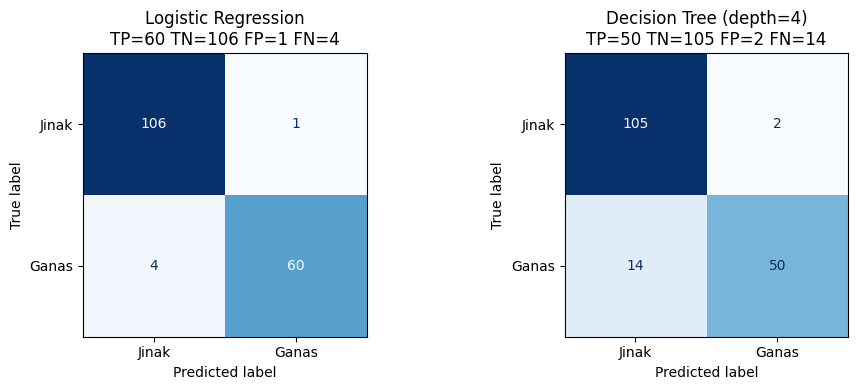

===== Logistic Regression =====
              precision    recall  f1-score   support

       Jinak       0.96      0.99      0.98       107
       Ganas       0.98      0.94      0.96        64

    accuracy                           0.97       171
   macro avg       0.97      0.96      0.97       171
weighted avg       0.97      0.97      0.97       171

===== Decision Tree (depth=4) =====
              precision    recall  f1-score   support

       Jinak       0.88      0.98      0.93       107
       Ganas       0.96      0.78      0.86        64

    accuracy                           0.91       171
   macro avg       0.92      0.88      0.90       171
weighted avg       0.91      0.91      0.90       171



In [7]:
# Confusion matrix kedua model
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (nama, p) in zip(axes, pred.items()):
    ConfusionMatrixDisplay(confusion_matrix(yb_test, p), display_labels=["Jinak", "Ganas"]).plot(ax=ax, colorbar=False, cmap="Blues")
    tn, fp, fn, tp = confusion_matrix(yb_test, p).ravel()
    ax.set_title(f"{nama}\nTP={tp} TN={tn} FP={fp} FN={fn}")
plt.tight_layout(); plt.show()

for nama, p in pred.items():
    print(f"===== {nama} =====")
    print(classification_report(yb_test, p, target_names=["Jinak", "Ganas"]))

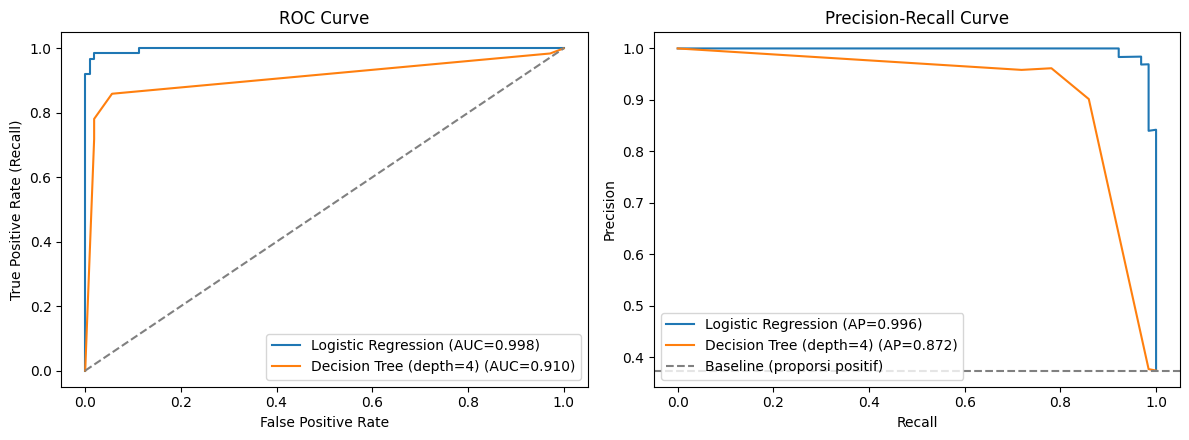

In [8]:
# ROC dan Precision-Recall curve kedua model dalam satu figure
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for nama in models:
    fpr, tpr, _ = roc_curve(yb_test, proba[nama])
    axes[0].plot(fpr, tpr, label=f"{nama} (AUC={auc(fpr, tpr):.3f})")
    prec, rec, _ = precision_recall_curve(yb_test, proba[nama])
    axes[1].plot(rec, prec, label=f"{nama} (AP={average_precision_score(yb_test, proba[nama]):.3f})")
axes[0].plot([0, 1], [0, 1], '--', color="gray")
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].set_title("ROC Curve"); axes[0].legend(loc="lower right")
axes[1].axhline(yb_test.mean(), ls="--", color="gray", label="Baseline (proporsi positif)")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve"); axes[1].legend(loc="lower left")
plt.tight_layout(); plt.show()

### Praktikum 2 — Perbandingan 3 Model dengan Stratified k-Fold CV (Praktikum 7.6)

Memakai dataset sintetis Bagian A (`X`, `y`, kelas 70:30), skor **F1** dari 5-Fold Stratified CV.

In [9]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

model_list = {"Logistic Regression": LogisticRegression(),
              "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
              "KNN": KNeighborsClassifier(n_neighbors=5)}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rekap = {}
for nama, model in model_list.items():
    skor = cross_val_score(model, X, y, cv=skf, scoring="f1")
    rekap[nama] = skor
    print(f"{nama}: F1 rata-rata = {skor.mean():.3f} (+/- {skor.std():.3f})")

Logistic Regression: F1 rata-rata = 0.799 (+/- 0.017)
Decision Tree: F1 rata-rata = 0.854 (+/- 0.034)
KNN: F1 rata-rata = 0.769 (+/- 0.042)


,Logistic Regression,Decision Tree,KNN
Fold 1,0.821,0.917,0.817
Fold 2,0.793,0.836,0.701
Fold 3,0.771,0.836,0.804
Fold 4,0.807,0.821,0.779
Fold 5,0.803,0.860,0.745
Rata-rata,0.799,0.854,0.769
Std,0.017,0.034,0.042


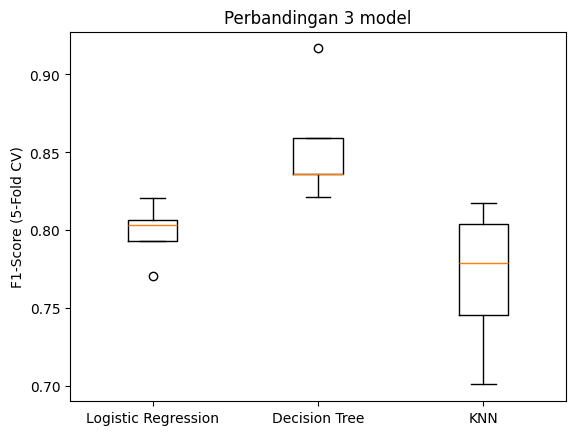

In [10]:
tabel = pd.DataFrame({n: s for n, s in rekap.items()}, index=[f"Fold {i}" for i in range(1, 6)])
tabel.loc["Rata-rata"] = tabel.mean(); tabel.loc["Std"] = tabel.iloc[:5].std(ddof=0)
display(tabel.round(3))
plt.boxplot([s for s in rekap.values()]); plt.xticks(range(1, len(rekap) + 1), list(rekap.keys()))
plt.ylabel("F1-Score (5-Fold CV)"); plt.title("Perbandingan 3 model"); plt.show()